### HR Analytics – Employee Attrition Analysis

### Problem Statement

Employee attrition is a major challenge for organizations.
When employees leave the company, it increases recruitment
and training costs and affects overall productivity.

The HR department wants to understand the reasons behind
employee attrition and identify the factors associated with
employees leaving the organization.

This project analyzes employee data to identify attrition
patterns and provide data-driven recommendations to improve
employee retention.

### ## Project Objectives

1. Analyze overall employee attrition.
2. Identify departments with higher attrition.
3. Analyze the relationship between salary and attrition.
4. Understand the impact of job satisfaction and overtime.
5. Identify employee characteristics associated with attrition.
6. Provide recommendations to improve employee retention.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_csv('HR-Employee.csv')
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [7]:
df.shape

(1470, 35)

In [8]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [10]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [11]:
df.dtypes.value_counts()

int64    26
str       9
Name: count, dtype: int64

In [12]:
# Data Dictionary

pd.set_option('display.max_rows', None)

data_dictionary = pd.DataFrame({
    'Column_Name': df.columns,
    'Data_Type': df.dtypes.astype(str).values,
    'Unique_Values': df.nunique().values
})

data_dictionary

,Column_Name,Data_Type,Unique_Values
0,Age,int64,43
1,Attrition,str,2
2,BusinessTravel,str,3
3,DailyRate,int64,886
4,Department,str,3
5,DistanceFromHome,int64,29
6,Education,int64,5
7,EducationField,str,6
8,EmployeeCount,int64,1
9,EmployeeNumber,int64,1470


In [13]:
missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_report = pd.DataFrame({
    'Missing_Count': missing_values,
    'Missing_Percentage': missing_percentage
})

missing_report

,Missing_Count,Missing_Percentage
Age,0,0.0
Attrition,0,0.0
BusinessTravel,0,0.0
DailyRate,0,0.0
Department,0,0.0
DistanceFromHome,0,0.0
Education,0,0.0
EducationField,0,0.0
EmployeeCount,0,0.0
EmployeeNumber,0,0.0


In [14]:
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


In [15]:
constant_columns = [
    col for col in df.columns
    if df[col].nunique() == 1
]

print("Constant Columns:", constant_columns)

Constant Columns: ['EmployeeCount', 'Over18', 'StandardHours']


In [16]:
df.drop(
    columns=['EmployeeCount', 'Over18', 'StandardHours'],
    inplace=True
)

In [17]:
df.shape

(1470, 32)

In [18]:
df['EmployeeNumber'].nunique()

1470

In [19]:
df['EmployeeNumber'].is_unique

True

In [20]:
df['Attrition'].value_counts()


Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [21]:
df['Attrition'].value_counts(normalize=True).mul(100).round(2)

Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64

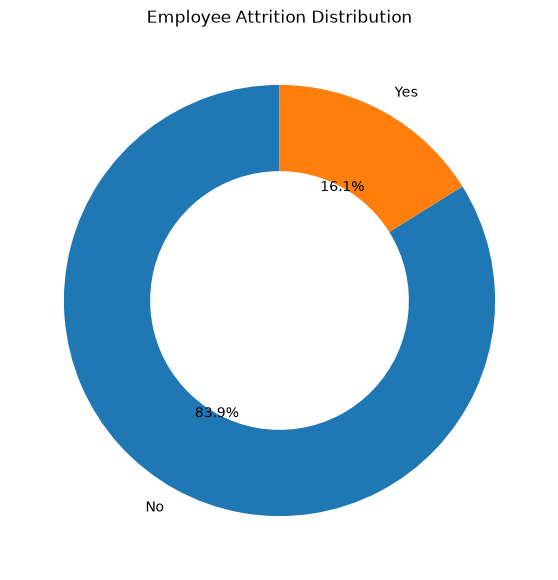

In [22]:
attrition_counts = df['Attrition'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    attrition_counts,
    labels=attrition_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4}
)

plt.title('Employee Attrition Distribution')
plt.show()

In [23]:
df['Age'].describe()

count    1470.000000
mean       36.923810
std         9.135373
min        18.000000
25%        30.000000
50%        36.000000
75%        43.000000
max        60.000000
Name: Age, dtype: float64

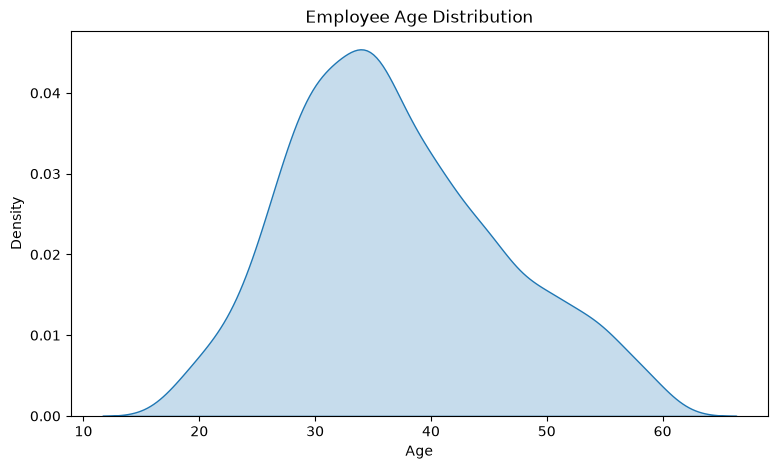

In [24]:
# Age Distribution using KDE

plt.figure(figsize=(9,5))

sns.kdeplot(
    data=df,
    x='Age',
    fill=True
)

plt.title('Employee Age Distribution')
plt.xlabel('Age')
plt.ylabel('Density')
plt.show()

In [25]:
# Age Group Segmentation

age_groups = pd.cut(
    df['Age'],
    bins=[18, 30, 40, 50, 60],
    labels=['18-30', '31-40', '41-50', '51-60'],
    include_lowest=True
)

age_groups.value_counts().sort_index()

Age
18-30    386
31-40    619
41-50    322
51-60    143
Name: count, dtype: int64

In [26]:
# Age Group Analysis

age_attrition = pd.crosstab(
    age_groups,
    df['Attrition'],
    normalize='index'
) * 100

age_attrition.round(2)

Attrition,No,Yes
Age,,
18-30,74.09,25.91
31-40,86.27,13.73
41-50,89.44,10.56
51-60,87.41,12.59


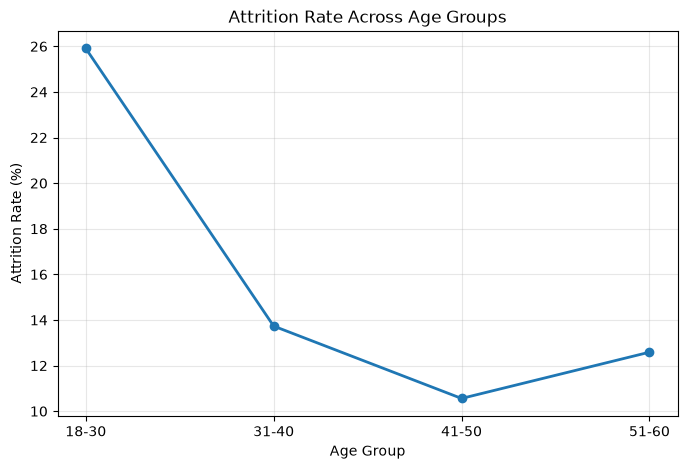

In [27]:
plt.figure(figsize=(8,5))

plt.plot(
    age_attrition.index.astype(str),
    age_attrition['Yes'],
    marker='o',
    linewidth=2
)

plt.title('Attrition Rate Across Age Groups')
plt.xlabel('Age Group')
plt.ylabel('Attrition Rate (%)')
plt.grid(alpha=0.3)
plt.show()

In [28]:
# Gender Diversity Analysis

df['Gender'].value_counts()

Gender
Male      882
Female    588
Name: count, dtype: int64

In [29]:
gender_attrition = pd.crosstab(
    df['Gender'],
    df['Attrition'],
    normalize='index'
) * 100

gender_attrition.round(2)

Attrition,No,Yes
Gender,,
Female,85.20,14.80
Male,82.99,17.01


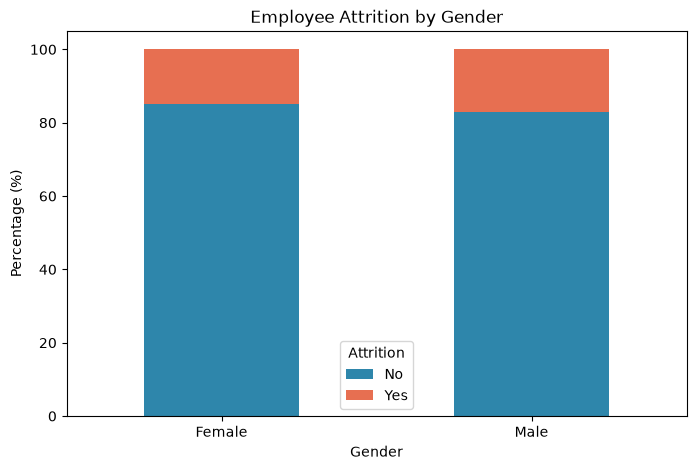

In [30]:
gender_attrition.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5),
    color=['#2E86AB', '#E76F51']
)

plt.title('Employee Attrition by Gender')
plt.xlabel('Gender')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Attrition')
plt.show()

Gender-wise attrition analysis shows that male employees
have a slightly higher attrition rate (17.01%) compared
to female employees (14.80%).

The difference is 2.21 percentage points. This indicates
a small variation in attrition across gender groups.
Further analysis of job roles, overtime, and work-life
balance may help understand this pattern.

In [31]:
# Department-wise Employee Analysis

df['Department'].value_counts()

Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

In [32]:
%pip install squarify

Note: you may need to restart the kernel to use updated packages.


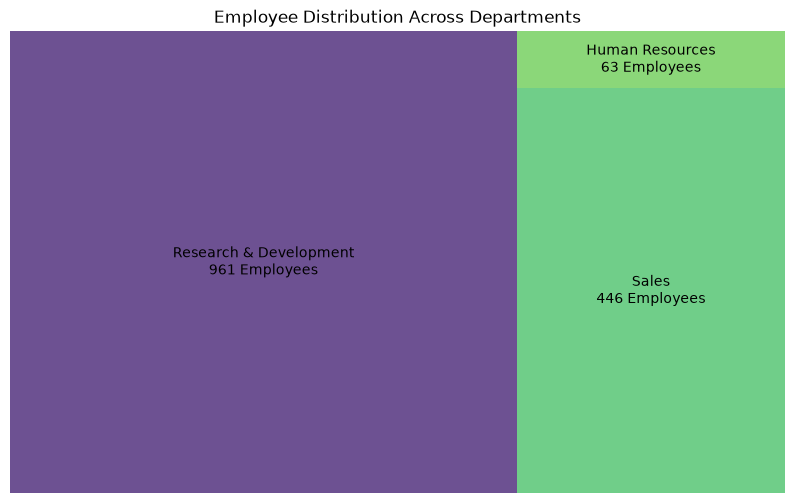

In [33]:
import squarify

department_counts = df['Department'].value_counts()

plt.figure(figsize=(10, 6))

squarify.plot(
    sizes=department_counts.values,
    label=[
        f'{dept}\n{count} Employees'
        for dept, count in department_counts.items()
    ],
    alpha=0.8
)

plt.title('Employee Distribution Across Departments')
plt.axis('off')
plt.show()

In [34]:
department_attrition = pd.crosstab(
    df['Department'],
    df['Attrition'],
    normalize='index'
) * 100

department_attrition.round(2)

Attrition,No,Yes
Department,,
Human Resources,80.95,19.05
Research & Development,86.16,13.84
Sales,79.37,20.63


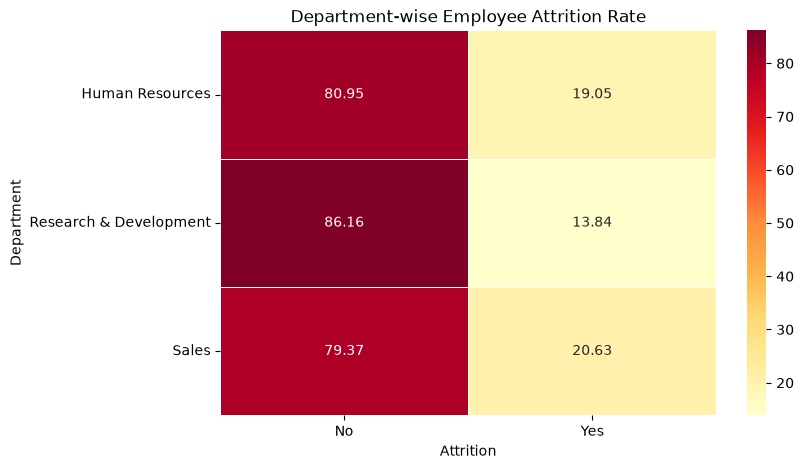

In [35]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    department_attrition,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Department-wise Employee Attrition Rate')
plt.xlabel('Attrition')
plt.ylabel('Department')
plt.show()

Sales department has the highest attrition rate at 20.63%,
followed by Human Resources at 19.05%.

Research & Development has the lowest attrition rate
at 13.84%.

HR management should investigate employee satisfaction,
workload, career growth, and working conditions,
especially in the Sales department.

In [36]:
# Job Role Analysis

df['JobRole'].value_counts()

JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

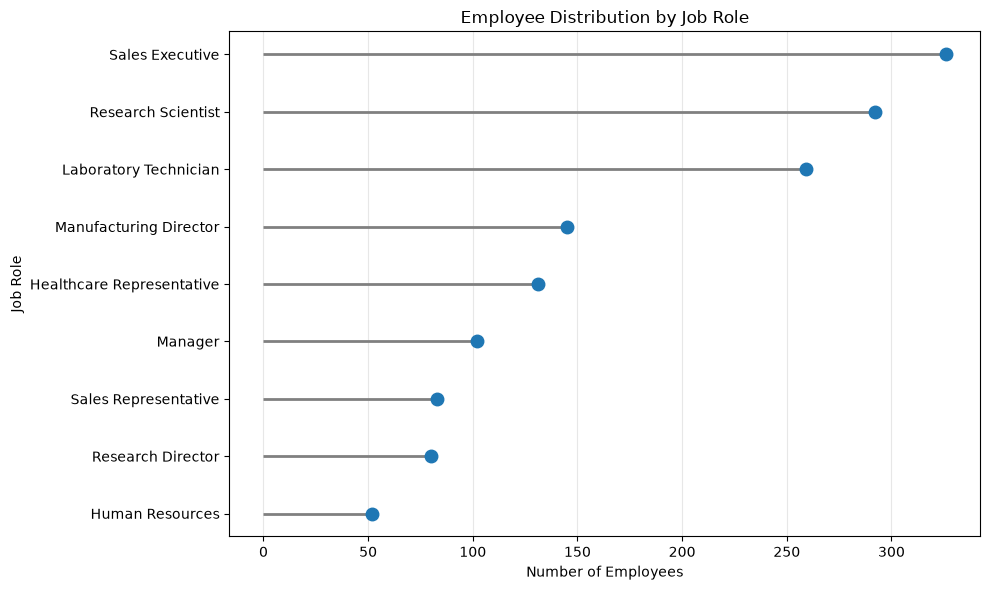

In [37]:
# Lollipop Chart Visualization

jobrole_counts = df['JobRole'].value_counts().sort_values()

plt.figure(figsize=(10, 6))

plt.hlines(
    y=jobrole_counts.index,
    xmin=0,
    xmax=jobrole_counts.values,
    color='gray',
    linewidth=2
)

plt.plot(
    jobrole_counts.values,
    jobrole_counts.index,
    'o',
    markersize=9
)

plt.title('Employee Distribution by Job Role')
plt.xlabel('Number of Employees')
plt.ylabel('Job Role')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [38]:
# Job Role-wise Attrition Analysis

jobrole_attrition = pd.crosstab(
    df['JobRole'],
    df['Attrition'],
    normalize='index'
) * 100

jobrole_attrition.round(2)

Attrition,No,Yes
JobRole,,
Healthcare Representative,93.13,6.87
Human Resources,76.92,23.08
Laboratory Technician,76.06,23.94
Manager,95.10,4.90
Manufacturing Director,93.10,6.90
Research Director,97.50,2.50
Research Scientist,83.90,16.10
Sales Executive,82.52,17.48
Sales Representative,60.24,39.76


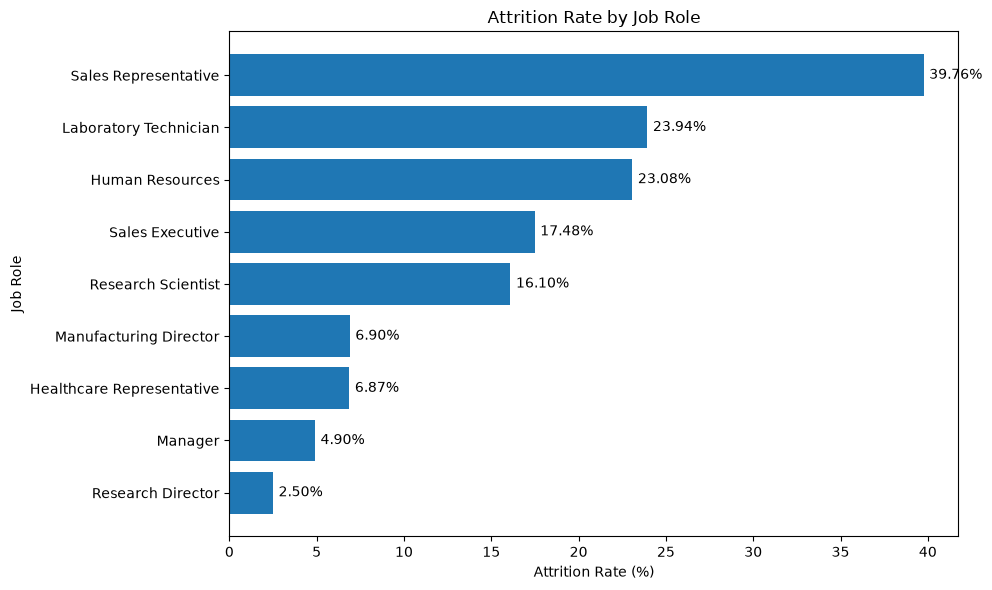

In [39]:
jobrole_attrition_sorted = jobrole_attrition['Yes'].sort_values()

plt.figure(figsize=(10, 6))

bars = plt.barh(
    jobrole_attrition_sorted.index,
    jobrole_attrition_sorted.values
)

plt.bar_label(bars, fmt='%.2f%%', padding=4)

plt.title('Attrition Rate by Job Role')
plt.xlabel('Attrition Rate (%)')
plt.ylabel('Job Role')
plt.tight_layout()
plt.show()

Sales Representatives have the highest attrition rate
at 39.76%, followed by Laboratory Technicians at 23.94%
and Human Resources at 23.08%.

Research Directors have the lowest attrition rate
at 2.50%.

HR management should investigate the factors associated
with higher attrition in Sales Representative and
Laboratory Technician roles.

In [40]:
# Salary Analysis
# Salary Descriptive Statistics

df['MonthlyIncome'].describe()

count     1470.000000
mean      6502.931293
std       4707.956783
min       1009.000000
25%       2911.000000
50%       4919.000000
75%       8379.000000
max      19999.000000
Name: MonthlyIncome, dtype: float64

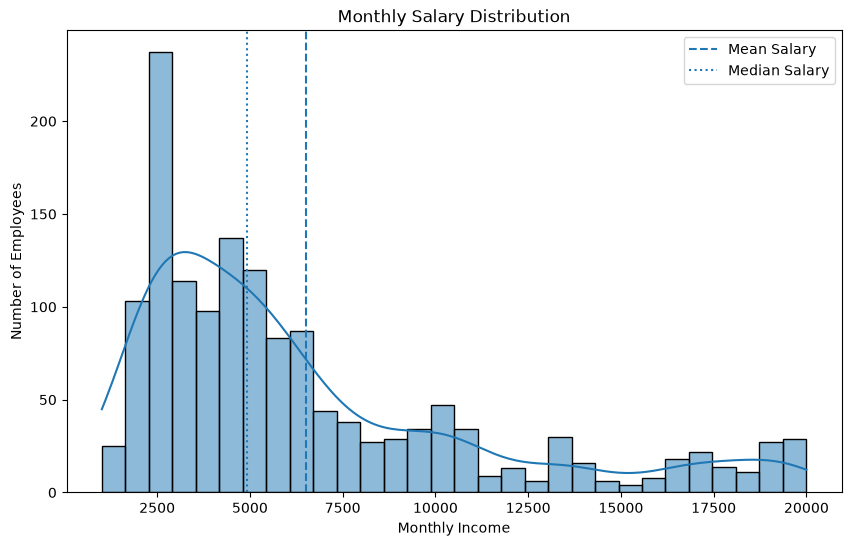

In [41]:
# Salary Distribution (Histogram + KDE)

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='MonthlyIncome',
    bins=30,
    kde=True
)

plt.axvline(
    df['MonthlyIncome'].mean(),
    linestyle='--',
    label='Mean Salary'
)

plt.axvline(
    df['MonthlyIncome'].median(),
    linestyle=':',
    label='Median Salary'
)

plt.title('Monthly Salary Distribution')
plt.xlabel('Monthly Income')
plt.ylabel('Number of Employees')
plt.legend()
plt.show()

In [42]:
# Salary Outlier Detection
# IQR Calculate

Q1 = df['MonthlyIncome'].quantile(0.25)
Q3 = df['MonthlyIncome'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 2911.0
Q3: 8379.0
IQR: 5468.0
Lower Limit: -5291.0
Upper Limit: 16581.0


In [43]:
outliers = df[
    (df['MonthlyIncome'] < lower_limit) |
    (df['MonthlyIncome'] > upper_limit)
]

print("Total Outliers:", len(outliers))
print("Outlier Percentage:", round(
    (len(outliers) / len(df)) * 100, 2
), "%")


Total Outliers: 114
Outlier Percentage: 7.76 %


In [44]:
outliers['MonthlyIncome'].sort_values(ascending=False)

190     19999
746     19973
851     19943
165     19926
568     19859
918     19847
749     19845
1242    19833
898     19740
956     19717
1009    19701
1331    19665
1154    19658
1401    19636
770     19627
814     19626
1129    19613
1116    19586
411     19566
45      19545
123     19537
233     19517
497     19513
473     19502
257     19436
1437    19431
716     19419
392     19406
1330    19392
1126    19331
1277    19328
326     19272
595     19246
766     19237
231     19232
244     19202
400     19197
922     19190
538     19189
955     19187
1377    19161
279     19144
535     19141
25      19094
869     19081
237     19068
1140    19049
270     19045
1264    19038
186     19033
29      18947
1443    18880
105     18844
913     18824
916     18789
62      18740
187     18722
899     18711
290     18665
858     18606
584     18430
741     18303
329     18300
904     18265
907     18213
477     18200
106     18172
936     18061
417     18041
653     17924
1374    17875
429   

In [45]:
outlier_joblevel = outliers['JobLevel'].value_counts().sort_index()

print(outlier_joblevel)


JobLevel
4    45
5    69
Name: count, dtype: int64


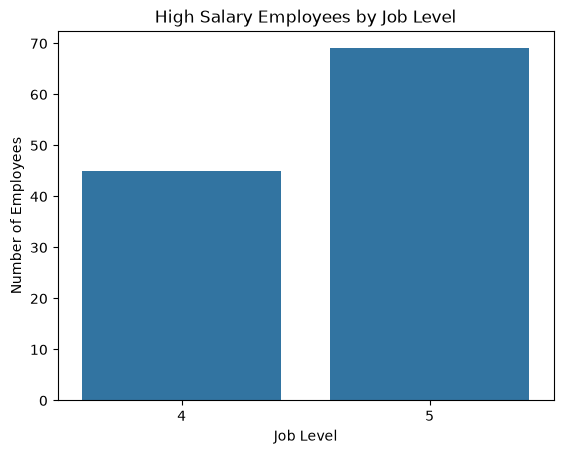

In [46]:
sns.countplot(
    data=outliers,
    x='JobLevel'
)

plt.title('High Salary Employees by Job Level')
plt.xlabel('Job Level')
plt.ylabel('Number of Employees')
plt.show()

In [47]:
df.groupby('JobLevel')['MonthlyIncome'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).round(2)

,count,mean,median,min,max
JobLevel,,,,,
1,543,2786.92,2670.0,1009,4968
2,534,5502.28,5340.0,2042,9998
3,218,9817.25,9980.0,5210,13757
4,106,15503.78,16154.0,11103,17924
5,69,19191.83,19232.0,18041,19999


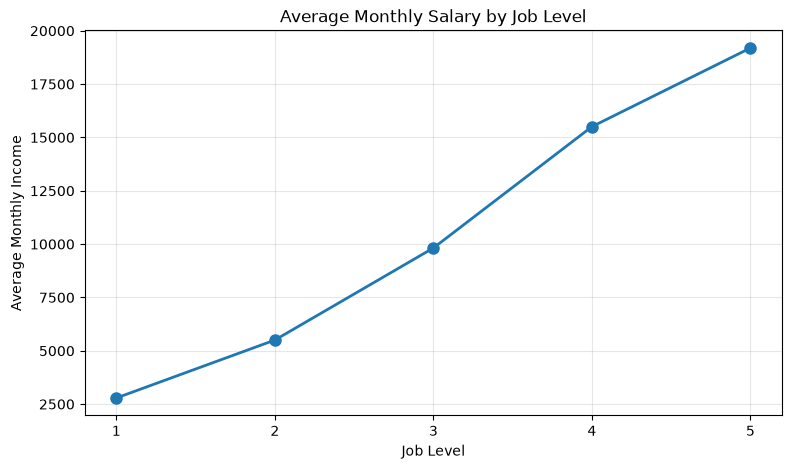

In [48]:
# Salary Trend by Job Level

joblevel_salary = df.groupby('JobLevel')['MonthlyIncome'].mean()

plt.figure(figsize=(9, 5))

plt.plot(
    joblevel_salary.index,
    joblevel_salary.values,
    marker='o',
    linewidth=2,
    markersize=8
)

plt.title('Average Monthly Salary by Job Level')
plt.xlabel('Job Level')
plt.ylabel('Average Monthly Income')
plt.xticks([1, 2, 3, 4, 5])
plt.grid(alpha=0.3)
plt.show()

The analysis shows a clear positive relationship between
Job Level and Monthly Income.

Employees at Job Level 5 have the highest average salary
of 19,191.83, while employees at Job Level 1 have the
lowest average salary of 2,786.92.

This indicates that employees at higher job levels
receive higher salaries in the organization.

In [49]:
# Salary vs Attrition Analysis

df['Salary_Group'] = pd.qcut(
    df['MonthlyIncome'],
    q=4,
    labels=['Low', 'Medium', 'High', 'Very High']
)

df['Salary_Group'].value_counts().sort_index()

Salary_Group
Low          369
Medium       366
High         367
Very High    368
Name: count, dtype: int64

In [50]:
salary_attrition = pd.crosstab(
    df['Salary_Group'],
    df['Attrition'],
    normalize='index'
) * 100

salary_attrition.round(2)

Attrition,No,Yes
Salary_Group,,
Low,70.73,29.27
Medium,85.79,14.21
High,89.37,10.63
Very High,89.67,10.33


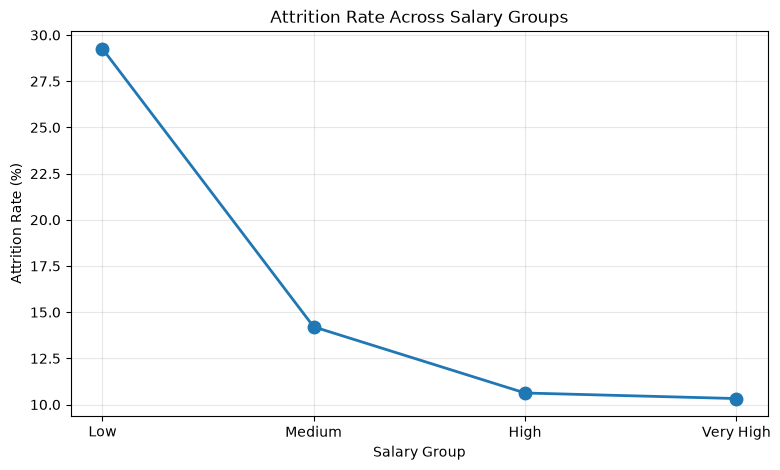

In [51]:
# Salary vs Attrition Trend

plt.figure(figsize=(9, 5))

plt.plot(
    salary_attrition.index.astype(str),
    salary_attrition['Yes'],
    marker='o',
    linewidth=2,
    markersize=9
)

plt.title('Attrition Rate Across Salary Groups')
plt.xlabel('Salary Group')
plt.ylabel('Attrition Rate (%)')
plt.grid(alpha=0.3)
plt.show()

The analysis shows that employees in the Low Salary
Group have the highest attrition rate at 29.27%.

The attrition rate decreases across higher salary groups,
with the Very High Salary Group showing the lowest
attrition rate at 10.33%.

This indicates a negative relationship between salary
group and employee attrition in this dataset.

In [52]:
# Job Satisfaction Analysis

df['JobSatisfaction'].value_counts().sort_index()

JobSatisfaction
1    289
2    280
3    442
4    459
Name: count, dtype: int64

In [53]:
# Job Satisfaction vs Attrition

satisfaction_attrition = pd.crosstab(
    df['JobSatisfaction'],
    df['Attrition'],
    normalize='index'
) * 100

satisfaction_attrition.round(2)

Attrition,No,Yes
JobSatisfaction,,
1,77.16,22.84
2,83.57,16.43
3,83.48,16.52
4,88.67,11.33


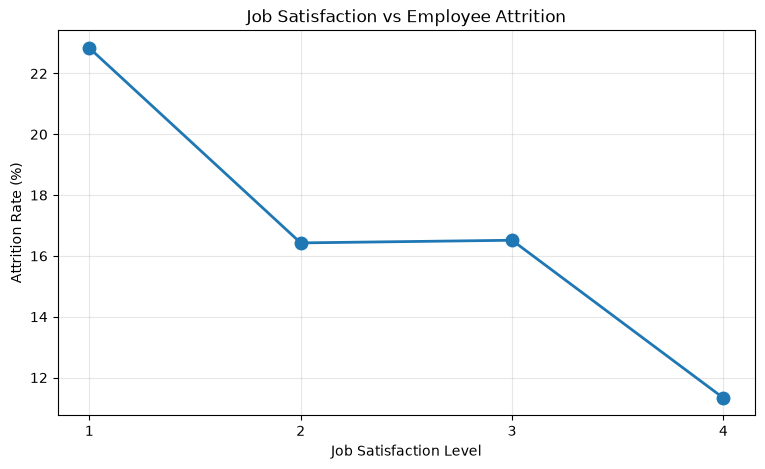

In [54]:
# Slope Chart

plt.figure(figsize=(9, 5))

plt.plot(
    satisfaction_attrition.index,
    satisfaction_attrition['Yes'],
    marker='o',
    linewidth=2,
    markersize=9
)

plt.title('Job Satisfaction vs Employee Attrition')
plt.xlabel('Job Satisfaction Level')
plt.ylabel('Attrition Rate (%)')
plt.xticks([1, 2, 3, 4])
plt.grid(alpha=0.3)
plt.show()

Employees with Job Satisfaction Level 1 have the highest
attrition rate at 22.84%, while employees with Level 4
have the lowest attrition rate at 11.33%.

The analysis indicates that higher job satisfaction
is associated with lower employee attrition.

HR management should focus on improving employee
satisfaction and workplace experience.

In [55]:
# Work-Life Balance Analysis

df['WorkLifeBalance'].value_counts().sort_index()

WorkLifeBalance
1     80
2    344
3    893
4    153
Name: count, dtype: int64

In [56]:
# Work-Life Balance vs Attrition

worklife_attrition = pd.crosstab(
    df['WorkLifeBalance'],
    df['Attrition'],
    normalize='index'
) * 100

worklife_attrition.round(2)

Attrition,No,Yes
WorkLifeBalance,,
1,68.75,31.25
2,83.14,16.86
3,85.78,14.22
4,82.35,17.65


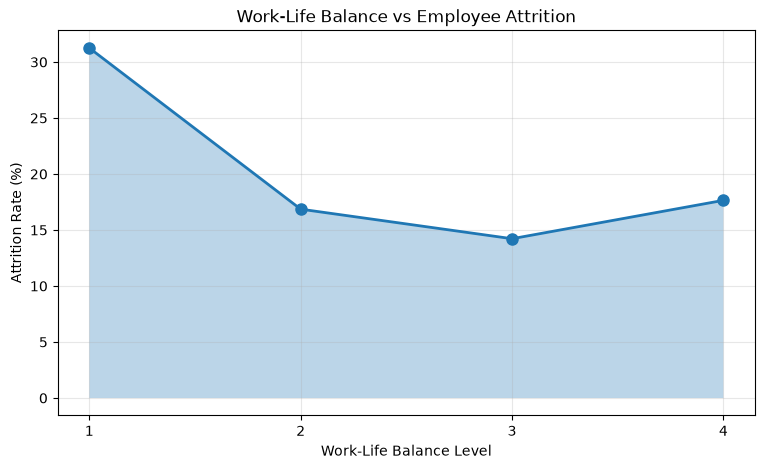

In [57]:
# Area Chart

plt.figure(figsize=(9, 5))

plt.fill_between(
    worklife_attrition.index,
    worklife_attrition['Yes'],
    alpha=0.3
)

plt.plot(
    worklife_attrition.index,
    worklife_attrition['Yes'],
    marker='o',
    linewidth=2,
    markersize=8
)

plt.title('Work-Life Balance vs Employee Attrition')
plt.xlabel('Work-Life Balance Level')
plt.ylabel('Attrition Rate (%)')
plt.xticks([1, 2, 3, 4])
plt.grid(alpha=0.3)
plt.show()

Employees with Work-Life Balance Level 1 have the
highest attrition rate at 31.25%.

Level 3 employees have the lowest attrition rate
at 14.22%.

The results suggest that poor work-life balance
is associated with higher employee attrition.
However, the pattern is not strictly decreasing
across all levels.

In [58]:
# OverTime Analysis

df['OverTime'].value_counts()


OverTime
No     1054
Yes     416
Name: count, dtype: int64

In [59]:
df['OverTime'].value_counts(normalize=True).mul(100).round(2)

OverTime
No     71.7
Yes    28.3
Name: proportion, dtype: float64

In [60]:
# OverTime vs Attrition

overtime_attrition = pd.crosstab(
    df['OverTime'],
    df['Attrition'],
    normalize='index'
) * 100

overtime_attrition.round(2)

Attrition,No,Yes
OverTime,,
No,89.56,10.44
Yes,69.47,30.53


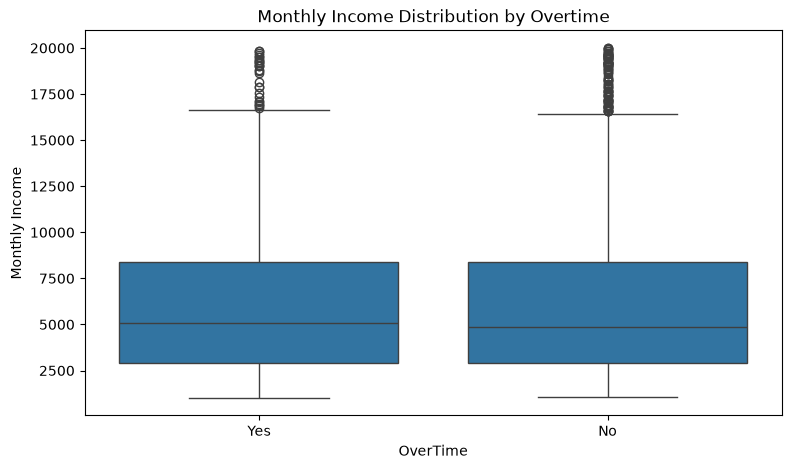

In [61]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='OverTime',
    y='MonthlyIncome'
)

plt.title('Monthly Income Distribution by Overtime')
plt.xlabel('OverTime')
plt.ylabel('Monthly Income')
plt.show()

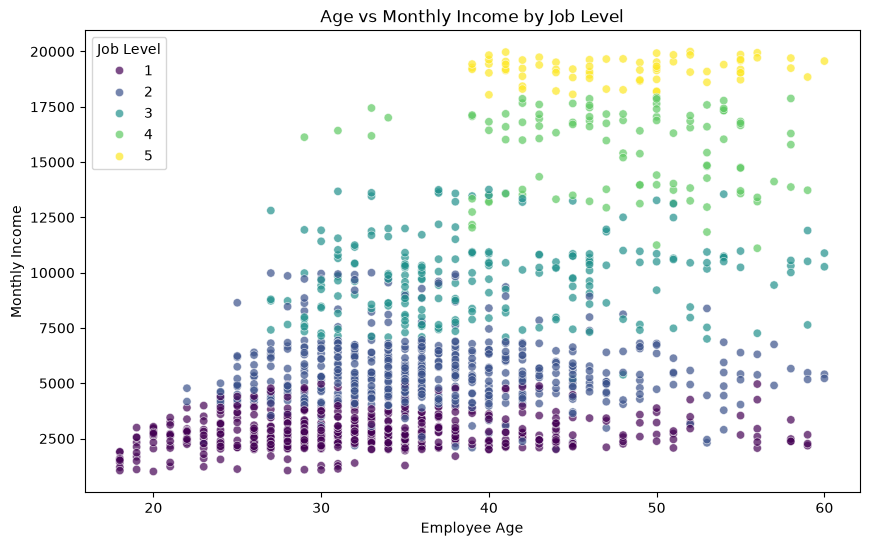

In [62]:
# Age vs Monthly Income Analysis

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Age',
    y='MonthlyIncome',
    hue='JobLevel',
    palette='viridis',
    alpha=0.7
)

plt.title('Age vs Monthly Income by Job Level')
plt.xlabel('Employee Age')
plt.ylabel('Monthly Income')
plt.legend(title='Job Level')
plt.show()

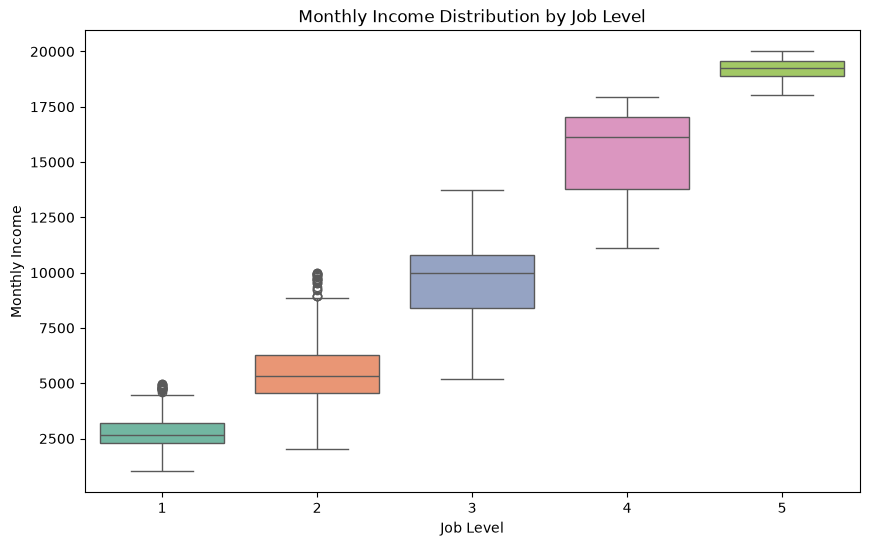

In [63]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='JobLevel',
    y='MonthlyIncome',
    hue='JobLevel',
    palette='Set2',
    legend=False
)

plt.title('Monthly Income Distribution by Job Level')
plt.xlabel('Job Level')
plt.ylabel('Monthly Income')
plt.show()